# Tarea puente L2 — Reproducir el congelado

**Equipo:** CASTILLO, HEREDIA, HUERFANO, ORTIZ, RIOS

Verificamos el archivo del curso y lo reconstruimos desde los ocho ZIP oficiales del DANE.

## 1 · Verificar el congelado

In [4]:
import pandas as pd

oficial = pd.read_csv("https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/main/datos/sipsa_mensual.csv.gz")
filtro = (oficial["mercado"] == "Manizales, Centro Galerías") & \
         (oficial["producto"] == "Plátano dominico hartón verde") & \
         (oficial["fecha"] == "2024-12")

print("Filas:", len(oficial), "| esperado: 666865")
print("Meses:", oficial["fecha"].nunique(), oficial["fecha"].min(), "a", oficial["fecha"].max(), "| esperado: 144, 2013-01 a 2024-12")
print("Ciudades:", oficial["ciudad"].nunique(), "| esperado: 71")
print("Productos:", oficial["producto"].nunique(), "| esperado: 385")
print("Plátano en Manizales, 2024-12:", oficial.loc[filtro, "precio_kg"].iloc[0], "| esperado: 2663")

Filas: 666865 | esperado: 666865
Meses: 144 2013-01 a 2024-12 | esperado: 144, 2013-01 a 2024-12
Ciudades: 71 | esperado: 71
Productos: 385 | esperado: 385
Plátano en Manizales, 2024-12: 2663.0 | esperado: 2663


## 2 · Reconstruirlo desde el DANE

Intentamos descargar los ocho ZIP con `congelar_sipsa.py`. **El pantallazo de estas dos celdas va en el informe.**

In [5]:
# (celda larga) Descarga los ZIP del DANE y reconstruye el archivo.
!wget -q https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/main/datos/congelar_sipsa.py
!python congelar_sipsa.py mi_sipsa.csv.gz 2>&1 | tail -3

  File "/usr/lib/python3.13/urllib/request.py", line 613, in http_error_default
    raise HTTPError(req.full_url, code, msg, hdrs, fp)
urllib.error.HTTPError: HTTP Error 401: Unauthorized


In [6]:
import os

if os.path.exists("mi_sipsa.csv.gz"):
    mio = pd.read_csv("mi_sipsa.csv.gz")
    print("Filas:", len(mio), "| ¿Idéntico al oficial?:", mio.equals(oficial))
else:
    print("No se creó mi_sipsa.csv.gz: la descarga del DANE no funcionó.")

No se creó mi_sipsa.csv.gz: la descarga del DANE no funcionó.


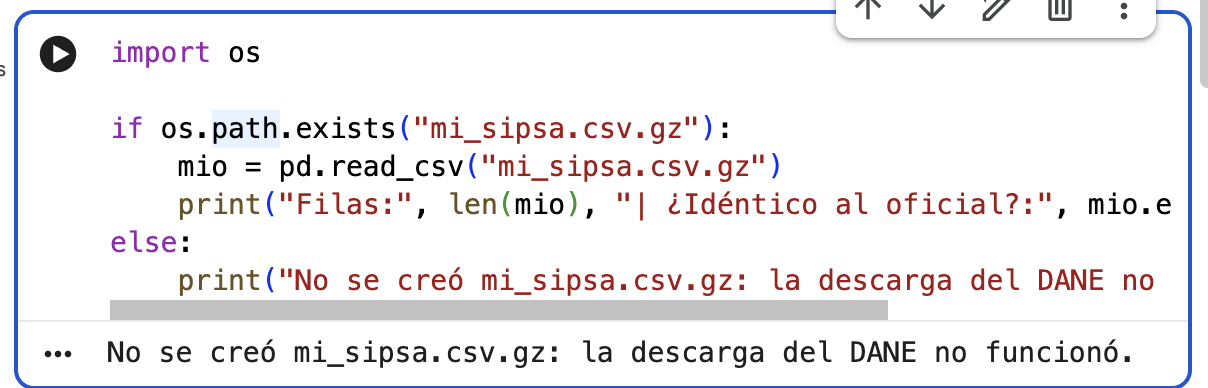

🗣️ **Resultado del 5 de noviembre de 2026:** el script no pudo reconstruir el archivo. Al descargar el primer ZIP, el servidor del DANE respondió `HTTP Error 401: Unauthorized`, es decir, no autorizó la descarga automática. Por eso no pudimos comparar los dos archivos.

Lo que sí verificamos en la sección 1: el archivo del curso tiene las filas, meses, ciudades, productos y el precio de control que publica `datos/README.md`. Esto confirma que el archivo coincide con lo publicado, pero no reemplaza reconstruirlo desde el DANE.

## 3 · Defensa del precio medio

🗣️ El precio promedio mayorista sirve para ver cómo cambian los precios en el tiempo, pero **no mide bien el costo de vida de una familia**, porque es el precio al que compran los comerciantes y no los hogares.

Pagaría más quien compra en tienda, en poca cantidad o lejos de la central, porque se suman el transporte, las pérdidas y la ganancia del tendero. También quien compra un día caro, porque el promedio mensual esconde esos días.

Para otros índices nos faltarían datos que este archivo no tiene. Para el **precio máximo** y la **mediana**, los precios individuales dentro del mes, porque de un promedio no se pueden recuperar. Para el **precio minorista**, precios tomados en tiendas y supermercados.